**Instructions:**

- Do not write your name on the assignment. Be careful about any warnings that might display some file path with your name included.
- Receiving help from classmates and/or ideas from Generative AI is allowed. **However, you must submit your own original work.**
- For questions that require coding, you need to write the relevant code and display its output. Your output should either be the direct answer to the question or clearly display the answer in it.
- For questions that require a written answer (sometimes along with the code), you need to put your answer in a Markdown cell. Writing the answer as a comment or as a print line is not acceptable.
- You need to render this file as HTML using Quarto and submit the HTML file. **Please note that this is a requirement and not optional.** A submission cannot be graded until it is properly rendered.

Import all the libraries and tools you need below.

In [2]:
# !pip install tensorflow
import tensorflow as tf
import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt

First, install [Tensorflow](https://www.tensorflow.org/) and [Keras](https://keras.io/) to your Python environment. Depending on your version, Keras comes with Tensorflow, so you might not need to install Keras separately. 

Make sure both libraries are installed properly. Check if you can import Tensorflow, Keras and any tool from Keras in the cell above.

If you have installation issues, you are expected to communicate this to the instructor promptly.

### 1)

Run the line below to load the MNIST data. This dataset consists of black-and-white images of handwritten digits. Answer the following questions to familiarize yourself with the dataset. (You will use this dataset for this and the next **four** exercise sets.)

- Print the shape of both the training and test datasets. How many dimensions does each dataset have?
- In tabular data, the dimensions represented the number of observations and variables, respectively. What do the dimensions represent in this dataset?
- How many images are there in the training and test datasets?
- What are the dimensions of each image?
- How many classes are there in the dataset? Print the set of the classes.

**(15 points)**

In [4]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training shape:", x_train.shape)
print("Test shape:", x_test.shape)

print("Training dimensions:", x_train.ndim)
print("Test dimensions:", x_test.ndim)

print("Training images:", len(x_train))
print("Test images:", len(x_test))

print("Image size:", x_train.shape[1:])

print("Classes:", np.unique(y_train))

Training shape: (60000, 28, 28)
Test shape: (10000, 28, 28)
Training dimensions: 3
Test dimensions: 3
Training images: 60000
Test images: 10000
Image size: (28, 28)
Classes: [0 1 2 3 4 5 6 7 8 9]


Both datasets have 3 dimensions. The dimensions represent the number of images, the height, and the width. The training set has 60,000 images and the test set has 10,000 images. Every image is 28 x 28 pixels and there are 10 classes, which are the digits from 0 to 9.

### 2)

[Visualize](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html) the images for three different digits. Would they be considered low or high-resolution images? What happens in terms of the dimensionality of the data as the resolution increases in an image dataset? **(10 points)**

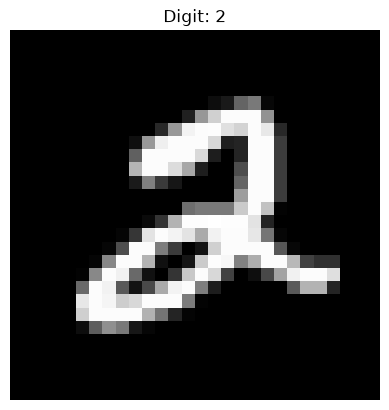

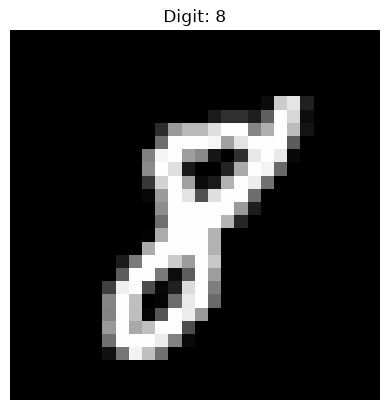

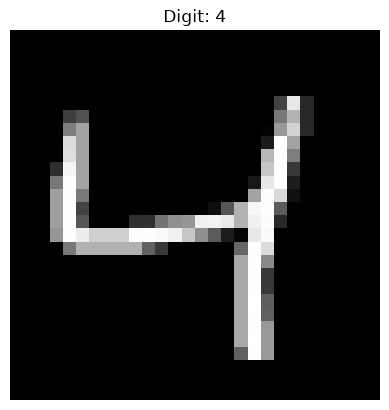

In [25]:
# Thought it would be cool to get random numbers
np.random.seed(0)
digits = np.random.choice(10, 3, replace=False)

for digit in digits:
    index = np.where(y_train == digit)[0][0]

    plt.imshow(x_train[index], cmap="grey")
    plt.title(f"Digit: {digit}")
    plt.axis("off")
    plt.show()

The images are low resolution because each image is only 28 × 28 pixels. As the resolution increases, the number of pixels increases, meaning each image has more features. This increases the dimensionality of the data when the images are flattened.

### 3)

An artificial neural network (ANN) cannot handle image data in its raw format, i.e. as a tensor. Therefore, you need to transform the image data into the tabular format that is used by all the classical Machine Learning (ML) models you learned in STAT 362 (and in STAT 301/303).

[Reshape](https://numpy.org/doc/stable/reference/generated/numpy.reshape.html) both the training and test dataset into two-dimensional matrices. Each observation should represent an image and each feature should represent a pixel value.

Print the `shape` of the reshaped matrices to check if the data is processed correctly.

**(7.5 points)**

In [15]:
x_train_flat = x_train.reshape(60000, 784)
x_test_flat = x_test.reshape(10000, 784)

print("Training shape:", x_train_flat.shape)
print("Test shape:", x_test_flat.shape)

Training shape: (60000, 784)
Test shape: (10000, 784)


### 4)

When the images in a dataset are processed into vectors by simply stacking their columns on top of one another, this is called **vectorization**. What information about the images is lost when an image dataset is processed with vectorization?

(This issue will be solved later by a special type of network architecture.)

**(7.5 points)**

Vectorizing images loses the explicit spatial structure of the image, so the relationships between neighboring pixels are no longer directly represented. Even though the pixel values are still there, the model cannot directly recognize their original 2D arrangement.

### 5)

Start an **empty** ANN model with the `Sequential` object. **(7.5 points)**

In [16]:
model = keras.Sequential()

### 6)

Add an input layer to the network. The number of nodes should be consistent with the data. **(12.5 points)**

**Note:** Be careful with rerunning the cell multiple times.

In [17]:
model.add(keras.Input(shape=(784,)))

### 7)

Add an output layer to the network. The number of nodes should be consistent with the data. **(12.5 points)**

**Notes:** 

- Do not use any other input than the number of nodes in the layer. You will build on this basic network in the upcoming exercise sets.
- Be careful with rerunning the cell multiple times.

In [18]:
model.add(keras.layers.Dense(10))

### 8)

Find out how many parameters you (already) have in this basic network by printing its `summary`. **(7.5 points)**

In [19]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

### 9)

How many layers does the network currently have? Does it have any hidden layers? Is it considered a "deep network"? **(5 points)**

The network has 2 layers, an input layer and an output layer and it does not have hidden layers. It is not considered a deep neural network because it does not have hidden layers.

### 10)

It is also useful to learn how to create a network in a less object-oriented way, which, for some special architectures, might be the only option.

Recreate the network you finalized in Question 7 by directly using a `Sequential` object with some inputs. You can follow [the guide on the Keras documentation](https://keras.io/guides/sequential_model/). **Note that your layers and their inputs should be the same as the network finalized in Question 7.** Reprint the network summary. You should have the same output as in Question 8 (with the name of the layer slightly different).

**(15 points)**

In [20]:
model2 = keras.Sequential([
    keras.Input(shape=(784,)),
    keras.layers.Dense(10)
])

model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)